### EDA

In [3]:
#import
from pathlib import Path
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import numpy as np


In [4]:
color_palette = matplotlib.colormaps['Set2'].colors

def rgb_to_hex(r, g, b):
    return '#{:02x}{:02x}{:02x}'.format(int(r*255), int(g*255), int(b*255))

palettehex = [rgb_to_hex(*c) for c in color_palette]

In [5]:
project_root = Path().resolve()
data_path = Path(project_root/ "data"/ "train.csv")

df = pd.read_csv(data_path)

### First glimpse

In [6]:
df.head()

,nom_du_projet,resume_du_projet,montant_engage,numero_ej,numero_operateur,opérateur,demarche,nom_region,nom_departement,code_departement,...,siret,activitePrincipale,codePostal,dateCreation,categorieEntreprise,trancheEffectifsUniteLegale,societeMissionUniteLegale,etatAdministratifEtablissement,anneeEffectifsEtablissement,economieSocialeSolidaireUniteLegale
0,"Changement des fenêtres ,des portes et pose de...","Suite aux différents audits, il convient de fi...",20710.00,2.104489e+09,NaN,NaN,Rénovation énergétique des bâtiments publics l...,Normandie,Eure,27,...,2.000561e+13,84.11Z,27160.0,2016-01-01,PME,12,NaN,A,2023.0,N
1,ZAC Bernard Duval,La ZAC Claude Bernard / Alexandre Duval à Renn...,200000.00,2.104469e+09,NaN,NaN,Recyclage foncier,Bretagne,Ille-et-Vilaine,35,...,5.231896e+13,42.99Z,35200.0,2010-05-10,ETI,03,NaN,A,2023.0,N
2,Travaux d'urgence de confortement et d'aménage...,Suites aux intempéries du début du mois de déc...,14157.02,2.104386e+09,NaN,NaN,Appui aux collectivités de montagne soumises à...,Provence-Alpes-Côte d'Azur,Hautes-Alpes,05,...,2.000673e+13,84.11Z,5230.0,2017-01-01,PME,12,NaN,A,2023.0,N
3,Rénovation thermique de l'école de GERBEPAL - ...,La commune de GERBÉPAL souhaite rénover le bât...,202019.00,2.104371e+09,NaN,NaN,Rénovation énergétique des bâtiments publics l...,Grand Est,Vosges,88,...,2.188020e+13,84.11Z,88430.0,1999-12-25,PME,11,NaN,A,2023.0,N
4,Rénovation énergétique du Centre Omnisport de ...,Situé à proximité du quartier de Marbé au nord...,587251.00,2.104409e+09,NaN,NaN,Rénovation énergétique des bâtiments publics l...,Bourgogne-Franche-Comté,Saône-et-Loire,71,...,2.171027e+13,84.11Z,71000.0,1983-03-01,ETI,42,NaN,A,2023.0,N


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7094 entries, 0 to 7093
Data columns (total 25 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   nom_du_projet                        7094 non-null   object 
 1   resume_du_projet                     6917 non-null   object 
 2   montant_engage                       7094 non-null   float64
 3   numero_ej                            6025 non-null   float64
 4   numero_operateur                     1072 non-null   object 
 5   opérateur                            1072 non-null   object 
 6   demarche                             6962 non-null   object 
 7   nom_region                           6929 non-null   object 
 8   nom_departement                      6929 non-null   object 
 9   code_departement                     6929 non-null   object 
 10  siret_beneficiaire                   6930 non-null   float64
 11  raison_sociale_beneficiaire   

In [8]:
for col in df.select_dtypes('object').columns:
    df[col] = df[col].astype('category')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7094 entries, 0 to 7093
Data columns (total 25 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   nom_du_projet                        7094 non-null   category
 1   resume_du_projet                     6917 non-null   category
 2   montant_engage                       7094 non-null   float64 
 3   numero_ej                            6025 non-null   float64 
 4   numero_operateur                     1072 non-null   category
 5   opérateur                            1072 non-null   category
 6   demarche                             6962 non-null   category
 7   nom_region                           6929 non-null   category
 8   nom_departement                      6929 non-null   category
 9   code_departement                     6929 non-null   category
 10  siret_beneficiaire                   6930 non-null   float64 
 11  raison_sociale_be

It becomes obvious from the basic information about the dataset that most of the variables are categorical variables. Also variables `societeMissionUniteLegale` and `numero_operateur`/`operateur` require further attention.

In [9]:
df.columns

for col in df.columns:
    df.columns = df.columns.str.replace(' ', '_').str.lower()
    df.columns = df.columns.str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')


This step is needed to treat the `trancheeffectifsunitelegale` values according to its type. This variable represents the ordinal structure, however it contains NN value that correspond to false information.

In [10]:
df["trancheeffectifsunitelegale"].value_counts()
df['tranche_effectif'] = df['trancheeffectifsunitelegale'].replace('NN', 'false_info')
ordinal_map = {
    '00': 0,
    '01': 1,
    '02': 2,
    '03': 3,
    '11': 4,
    '12': 5,
    '21': 6,
    '22': 7,
    '31': 8,
    '32': 9,
    '41': 10,
    '42': 11,
    '51': 12,
    '52': 13,
    '53': 14
}

df['tranche_effectif_ord'] = df['trancheeffectifsunitelegale'].map(ordinal_map)
df['is_false_info'] = (df['trancheeffectifsunitelegale'] == 'NN').astype(int)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7094 entries, 0 to 7093
Data columns (total 28 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   nom_du_projet                        7094 non-null   category
 1   resume_du_projet                     6917 non-null   category
 2   montant_engage                       7094 non-null   float64 
 3   numero_ej                            6025 non-null   float64 
 4   numero_operateur                     1072 non-null   category
 5   operateur                            1072 non-null   category
 6   demarche                             6962 non-null   category
 7   nom_region                           6929 non-null   category
 8   nom_departement                      6929 non-null   category
 9   code_departement                     6929 non-null   category
 10  siret_beneficiaire                   6930 non-null   float64 
 11  raison_sociale_be

/var/folders/4t/1cnp1cq57sscygp0x865kkj80000gn/T/ipykernel_19145/37118445.py:2: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df['tranche_effectif'] = df['trancheeffectifsunitelegale'].replace('NN', 'false_info')


The following stages will research the cardinality of the categorical variables.

In [11]:
from utilites import clean_text

categorical_cols = df.select_dtypes('category').columns

for col in df[categorical_cols]:
    df[col] = df[col].apply(clean_text)

In [12]:
unique_values = df[categorical_cols].nunique().sort_values(ascending=False).to_dict()

low_cardinality = []
high_cardinality = []
mid_cardinality = []

for var, count in unique_values.items():
    if count < 7:
        low_cardinality.append(var)
    elif count >= 7 and count < 30:
        mid_cardinality.append(var) 
    else:
        high_cardinality.append(var)
    print(f"{var}: {count} unique values")


resume_du_projet: 6772 unique values
nom_du_projet: 6660 unique values
raison_sociale_beneficiaire: 5139 unique values
code_commune: 4486 unique values
nom_commune: 4454 unique values
numero_operateur: 1072 unique values
datecreation: 1000 unique values
activiteprincipale: 146 unique values
nom_departement: 106 unique values
code_departement: 106 unique values
forme_juridique_beneficiaire: 61 unique values
nom_region: 23 unique values
demarche: 17 unique values
trancheeffectifsunitelegale: 15 unique values
tranche_effectif: 15 unique values
operateur: 7 unique values
categorieentreprise: 3 unique values
economiesocialesolidaireunitelegale: 2 unique values
societemissionunitelegale: 1 unique values
etatadministratifetablissement: 1 unique values


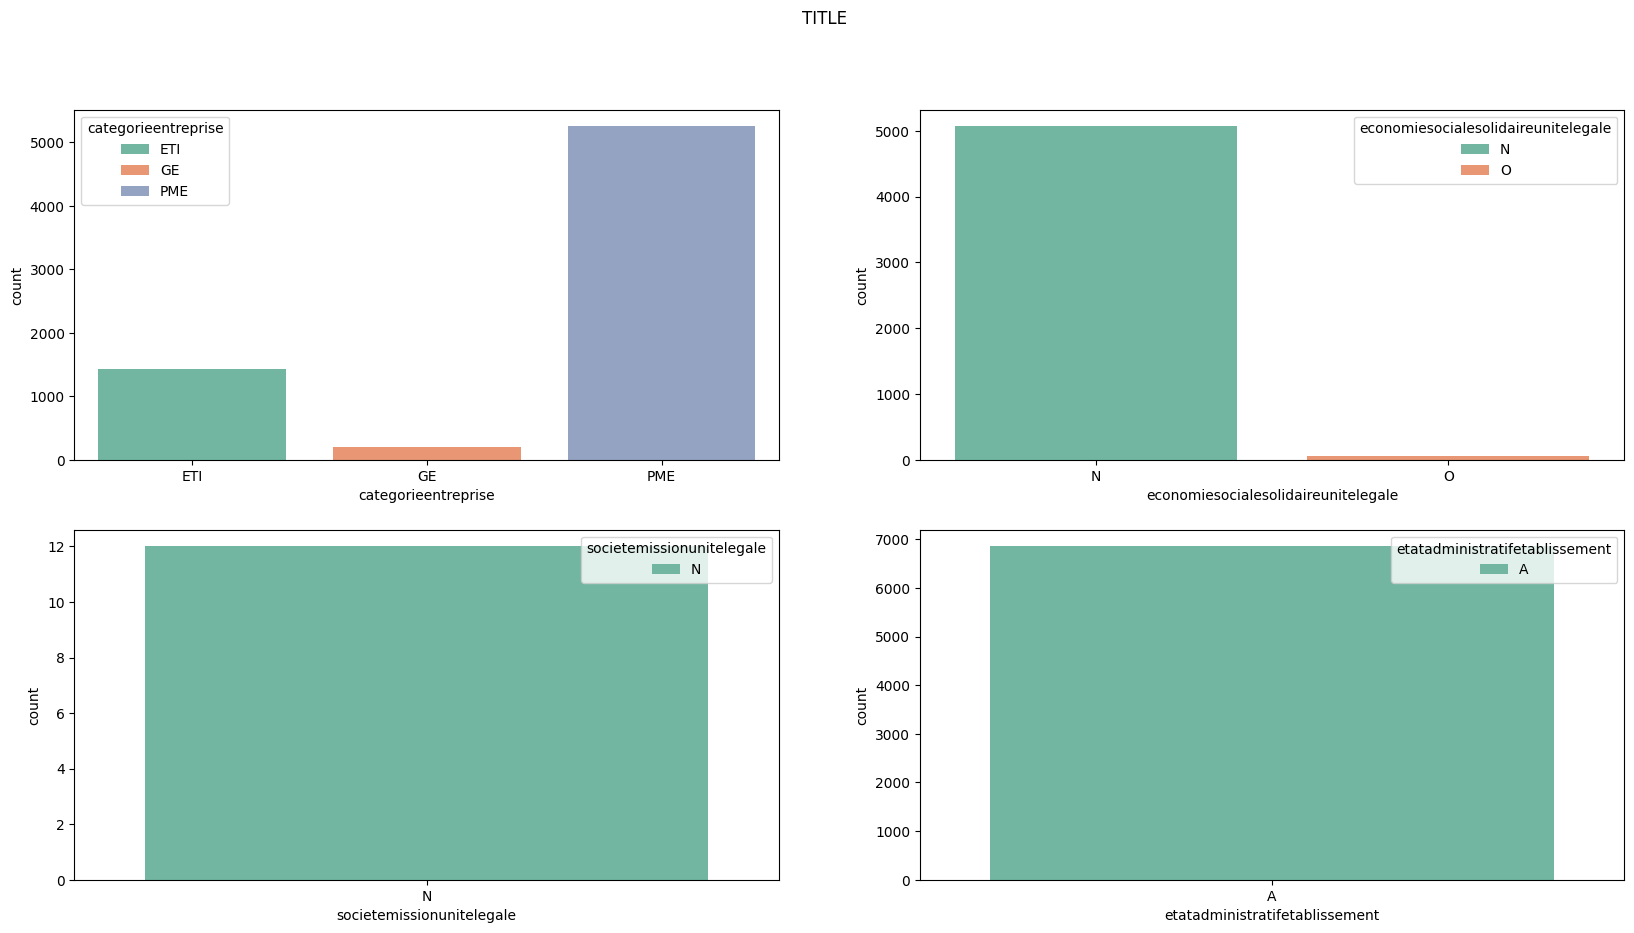

In [13]:
categorical_cols = df.select_dtypes('category').columns

fig, axes = plt.subplots(2, 2, figsize=(20, 10))
fig.suptitle('TITLE')
for i, col in enumerate(low_cardinality[:4]):
    sns.countplot(ax=axes[i // 2, i % 2], x=col, data=df, palette="Set2", hue=df[col])
plt.show()

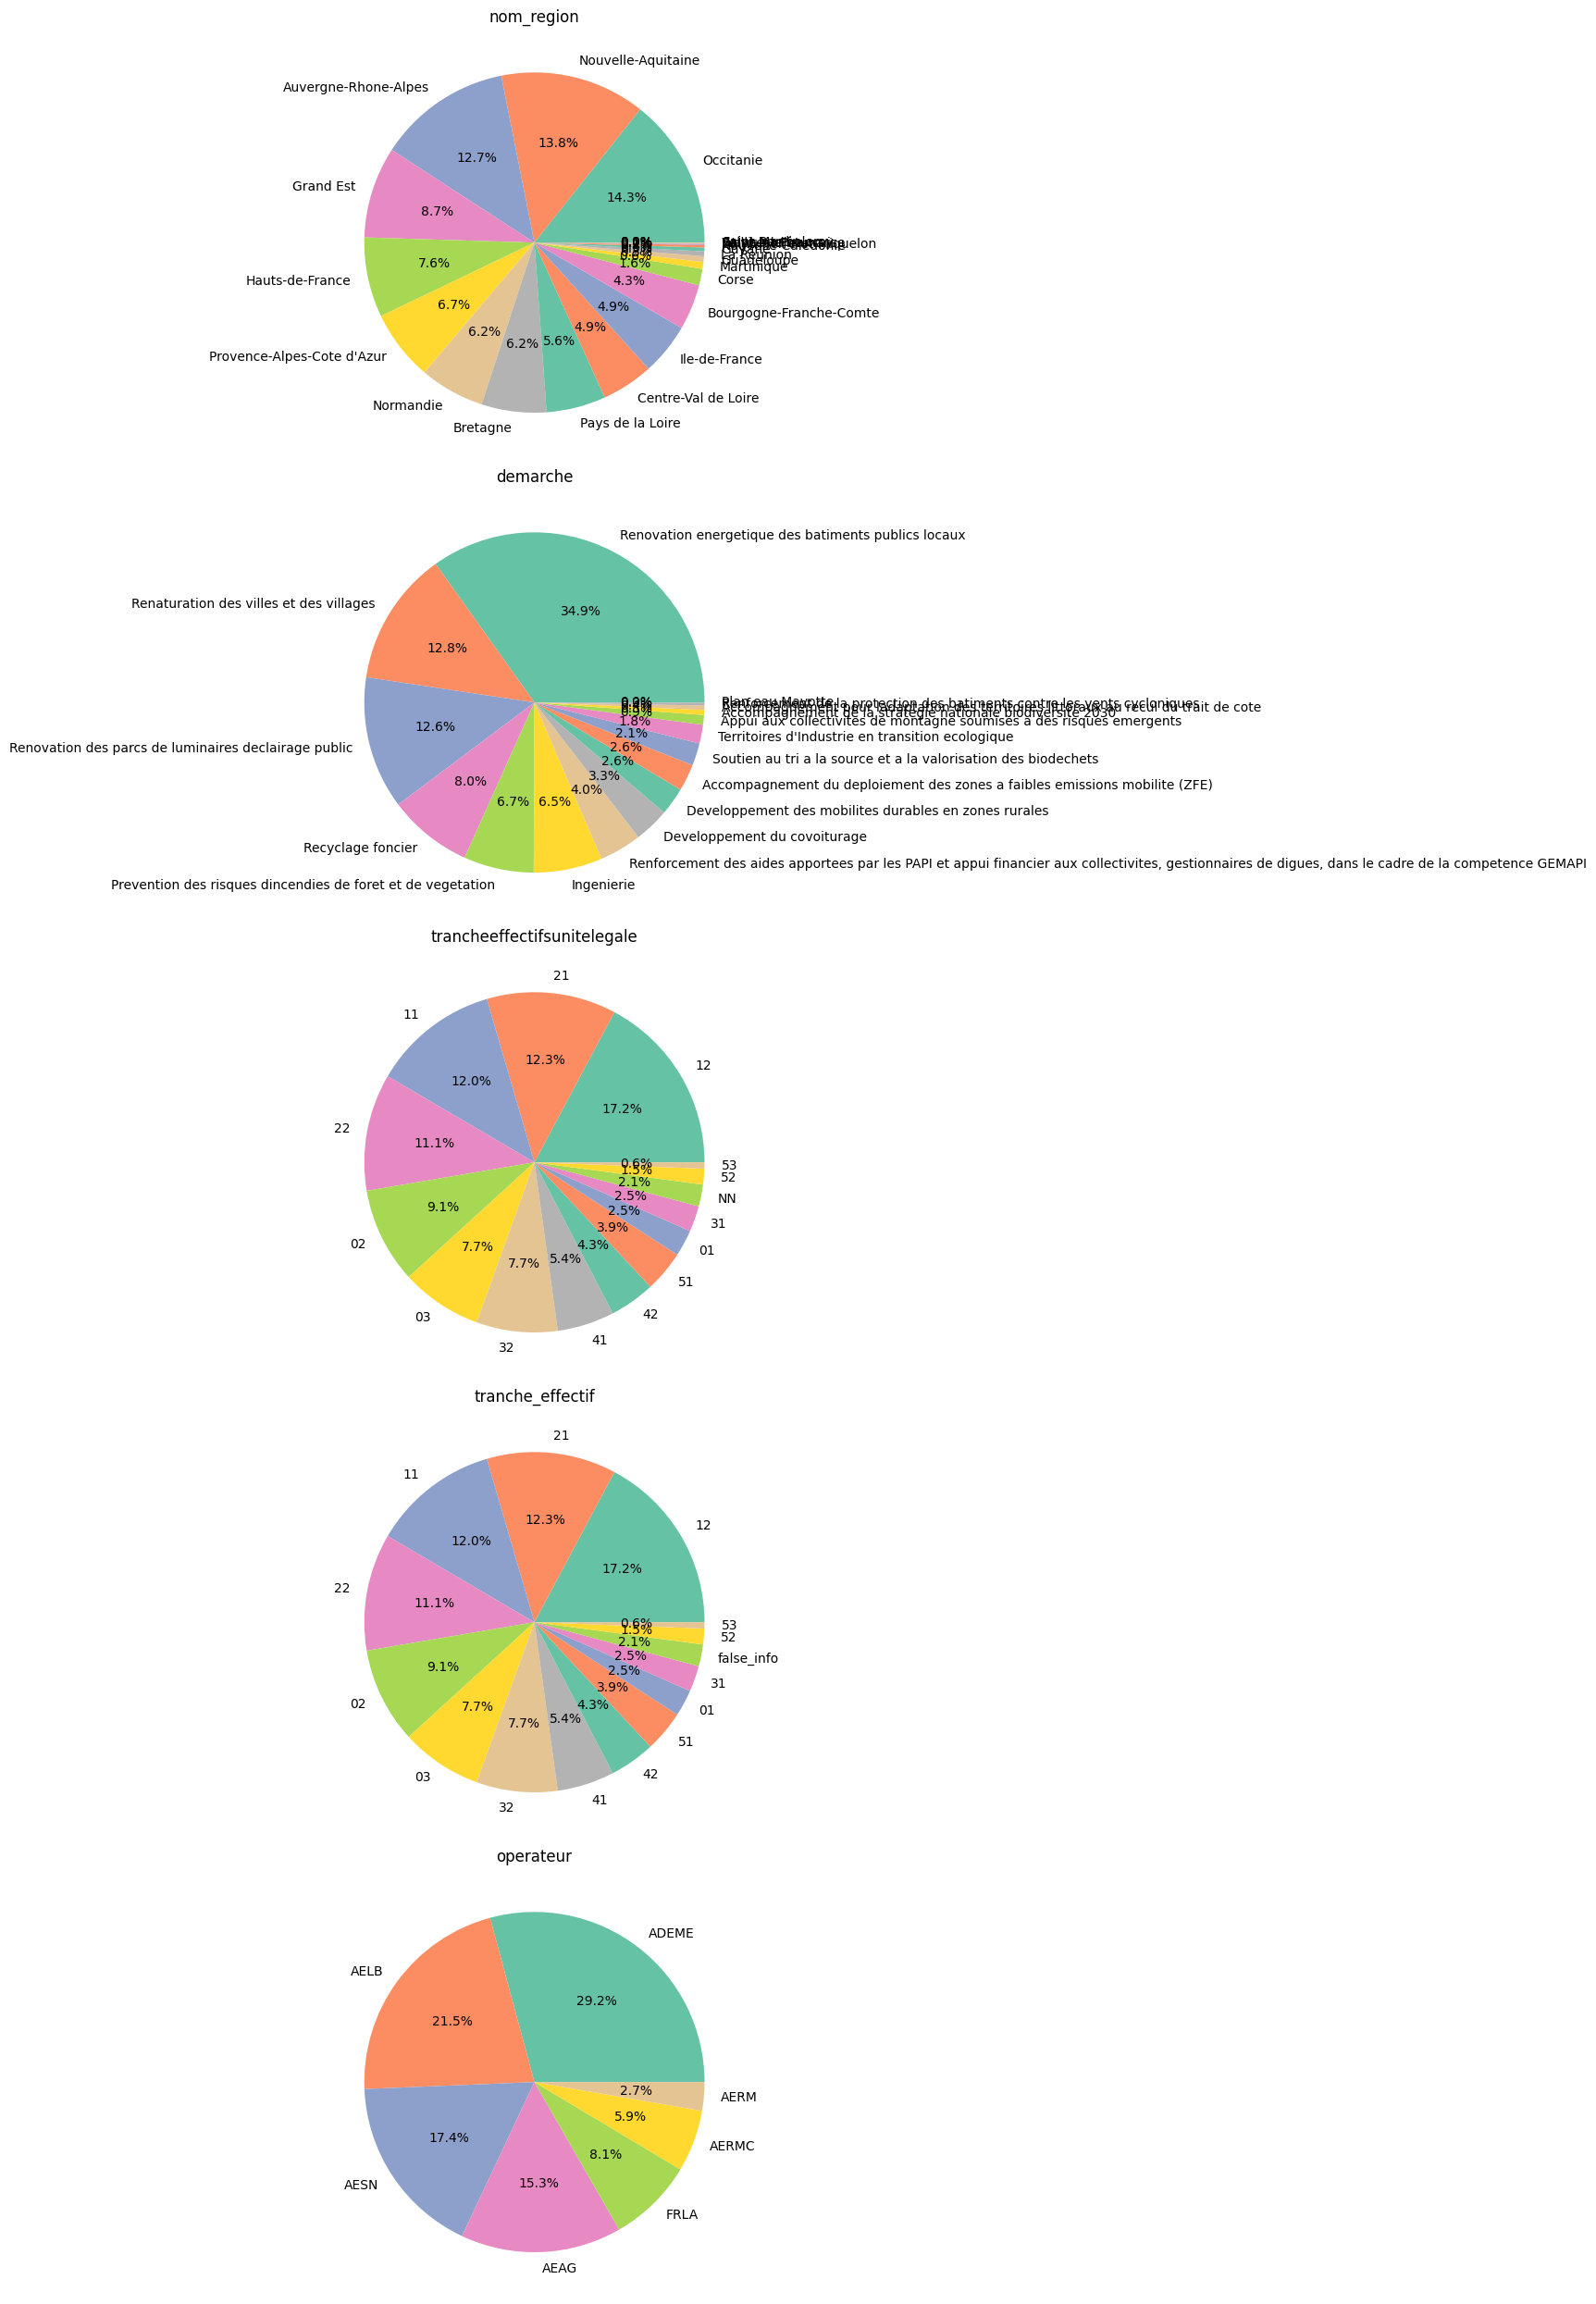

In [14]:
n_rows = len(mid_cardinality)

fig, axes = plt.subplots(n_rows, figsize=(15, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(mid_cardinality):
    df[col].value_counts().plot(
        kind='pie',
        ax=axes[i],
        title=col,
        autopct='%1.1f%%',
        colors=palettehex
    )
    axes[i].set_ylabel('')  # Remove y-label for cleaner look

# Hide extra subplots if odd number of plots
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

We have detected only 1 numerical variable which is a subsidy size. However, the age of the company is a subject to categorical-to-numerical transition (`dateCreation`).

In [15]:
df["montant_engage"].describe()

count    7.094000e+03
mean     1.818024e+05
std      3.776175e+05
min      2.875000e+02
25%      1.811075e+04
50%      6.324140e+04
75%      2.006882e+05
max      1.160000e+07
Name: montant_engage, dtype: float64

In [16]:
df["log_montant_engage"]= np.log1p(df["montant_engage"])


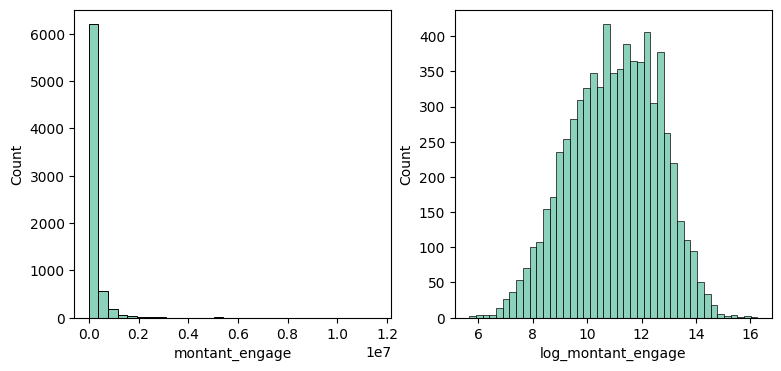

In [17]:
#Target variable distribution
fig, ax = plt.subplots(1,2,figsize=(9, 4))
sns.histplot(data=df, x="montant_engage", 
             color=palettehex[0], 
             ax=ax[0],
             bins=30)
sns.histplot(data=df, x="log_montant_engage", 
             color=palettehex[0], 
             ax=ax[1])
plt.show()

The target variable looks way more readable with the log tranformation applied.

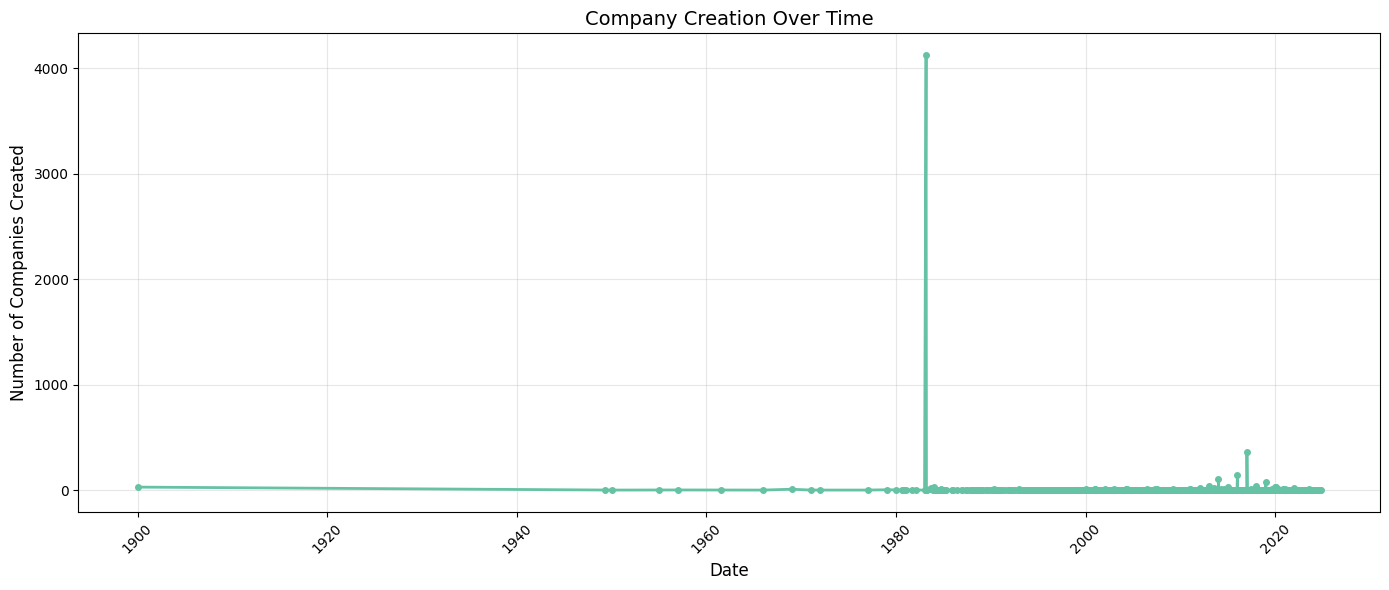

In [18]:
#Companies' age distribution
df["datecreation"] = pd.to_datetime(df["datecreation"], format='%Y-%m-%d')
df["creation_year"] = df["datecreation"].dt.year
df["year_month"] = df["datecreation"].dt.to_period('M').astype(str)

time_counts = df.groupby('datecreation').size().reset_index(name='count')
time_counts['datecreation'] = pd.to_datetime(time_counts['datecreation'])

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(time_counts['datecreation'], time_counts['count'], 
        color=palettehex[0], linewidth=2, marker='o', markersize=4)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Number of Companies Created', fontsize=12)
ax.set_title('Company Creation Over Time', fontsize=14)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

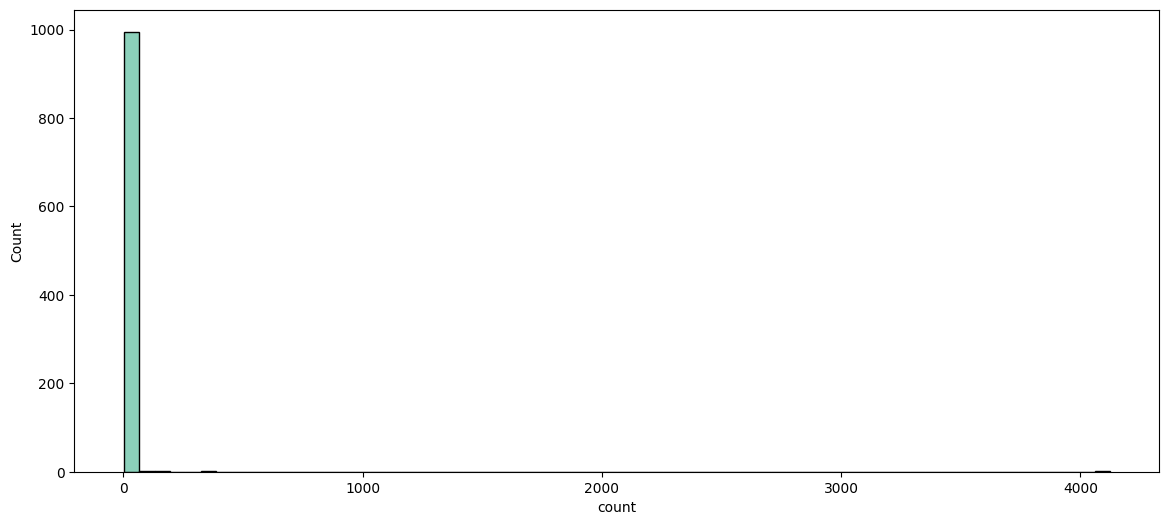

Maximum value 4124 found at index 20 corresponding to date 1983-03-01 00:00:00


In [19]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.histplot(data=time_counts, x="count", 
             color=palettehex[0], 
             ax=ax)
plt.show()

for i, val in enumerate(time_counts['count']):
    max_values = time_counts['count'].max()
    if val == max_values:
        print(f"Maximum value {val} found at index {i} corresponding to date {time_counts['datecreation'][i]}")

The anomalous date was detected. 4124 firms were created in this specific date with is considered to be abnormally extreme. We'll try to find some logical explanation of this outlier, otherwise, we'll need to get rid of it since it touches a significant amount of observation, or create a special category for this variable.

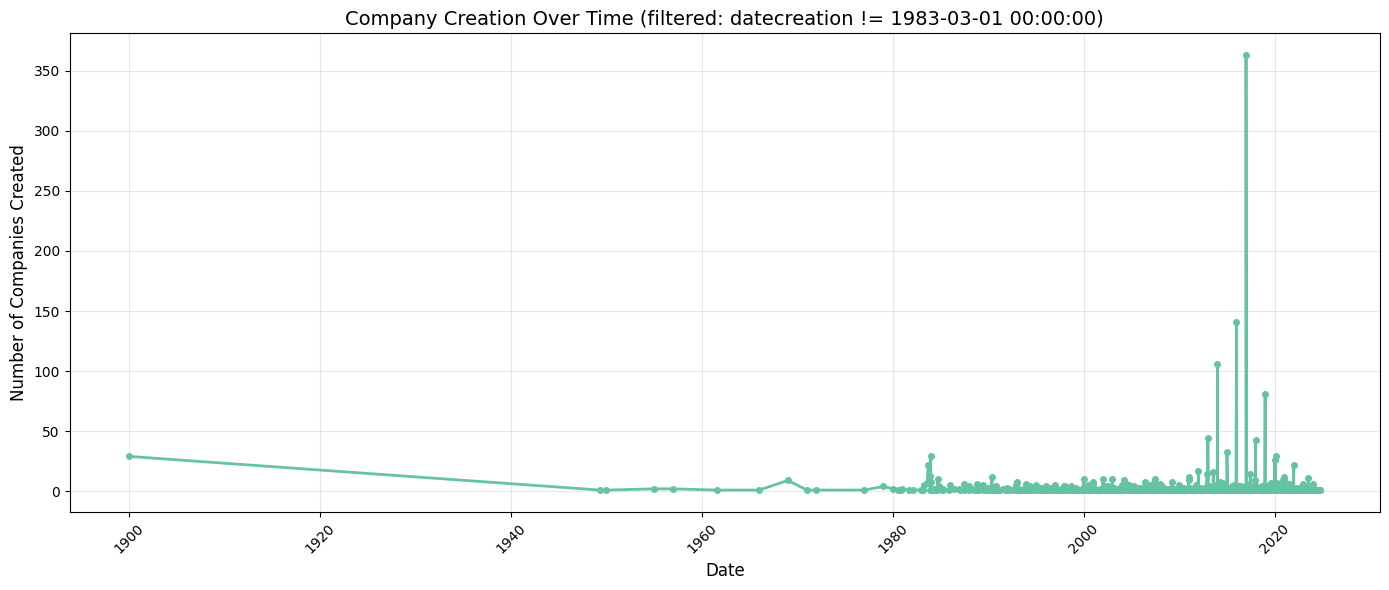

In [20]:
# Filter out extreme outliers
threshold = "1983-03-01 00:00:00"
time_counts_filtered = time_counts[time_counts['datecreation'] != threshold]

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(time_counts_filtered['datecreation'], time_counts_filtered['count'], 
        color=palettehex[0], linewidth=2, marker='o', markersize=4)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Number of Companies Created', fontsize=12)
ax.set_title(f'Company Creation Over Time (filtered: datecreation != {threshold})', fontsize=14)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
today = pd.Timestamp.today()
df["age_entreprise"] = (today - df["datecreation"]).dt.days / 365.25
df["age_entreprise_m"] = (today - df["datecreation"]).dt.days / 30.44

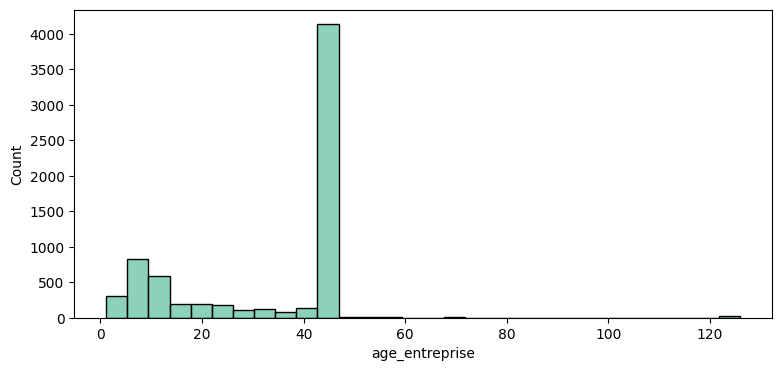

count    6929.000000
mean       32.239526
std        16.294109
min         1.138946
25%        13.935661
50%        42.773443
75%        42.773443
max       125.932923
Name: age_entreprise, dtype: float64

In [22]:
#Target variable distribution
fig, ax = plt.subplots(1,1,figsize=(9, 4))
sns.histplot(data=df, x="age_entreprise", 
             color=palettehex[0], 
             ax=ax,
             bins=30)
plt.show()

df["age_entreprise"].describe()

We will treat these extreme values as "input errors". Thus, we'll make a medium imputation and create a dummy for errors aside.

### NA check and treatment

In [23]:
na = df.isna().sum()/df.shape[0]*100

px.bar(na.sort_values(),
         title = "Pourcentage de valeurs manquantes par variable",
         color_discrete_sequence = palettehex[0:1],
         template='ggplot2',
         range_y = [0,100],
         width=800,
         labels={'value':'%', 'index':''},
         color=None
        ).update_traces(showlegend=False).update_xaxes(tickangle=45)

In [24]:
na = df.isna().sum()/df.shape[0]*100
na.sort_values()

nom_du_projet                           0.000000
year_month                              0.000000
montant_engage                          0.000000
log_montant_engage                      0.000000
is_false_info                           0.000000
demarche                                1.860727
code_commune                            1.860727
nom_commune                             1.860727
raison_sociale_beneficiaire             1.945306
forme_juridique_beneficiaire            1.945306
siret_beneficiaire                      2.311813
creation_year                           2.325909
tranche_effectif                        2.325909
trancheeffectifsunitelegale             2.325909
datecreation                            2.325909
age_entreprise                          2.325909
activiteprincipale                      2.325909
code_departement                        2.325909
nom_departement                         2.325909
nom_region                              2.325909
siret               

Before choosing candidates for the deletion, we'll take a look at the variables' meaning and try to understand if the fact that the variable is missing is something explained by its nature.

- `societemissionunitelegale`: Introduced only in 2019.
- `economiesocialesolidaireunitelegale`: Missing ≠ “unknown”; missing = “not part of the ESS perimeter and not declared”.
- `numero_operateur`: These are identifiers used only for specific legal setups
- `numero_ej`: Missing when there is no EJ separate from the legal unit, which happens in many cases.
- `age_entreprise`: imputed and a dummy added

So, these NAs are structural and we suppose that the model will loose a lot of necessary information with exclusion of these variables. We have decided to keep them selectively, and make imputation based on the meaning of each variable.

### Imputation and Clean-up

In [25]:
print(df['societemissionunitelegale'].value_counts(dropna=False))
print(df['anneeeffectifsetablissement'].value_counts(dropna=False))
print(df['numero_ej'].value_counts(dropna=False))
print(df['economiesocialesolidaireunitelegale'].value_counts(dropna=False))
print(df['operateur'].value_counts(dropna=False))

societemissionunitelegale
NaN    7082
N        12
Name: count, dtype: int64
anneeeffectifsetablissement
2023.0    6700
NaN        394
Name: count, dtype: int64
numero_ej
NaN             1069
2.104591e+09       4
2.104503e+09       2
2.104575e+09       2
2.104323e+09       2
                ... 
2.104565e+09       1
2.104598e+09       1
2.104371e+09       1
2.104320e+09       1
2.104414e+09       1
Name: count, Length: 6019, dtype: int64
economiesocialesolidaireunitelegale
N      5069
NaN    1966
O        59
Name: count, dtype: int64
operateur
NaN      6022
ADEME     313
AELB      230
AESN      186
AEAG      164
FRLA       87
AERMC      63
AERM       29
Name: count, dtype: int64


In [26]:
mask_placeholder = df['datecreation'] == "1983-03-01 00:00:00"
df['is_creation_unknown'] = mask_placeholder.astype(int)

df.loc[mask_placeholder, 'age_entreprise'] = np.nan
median_age = df['age_entreprise'].median()
df['age_entreprise_filled'] = df['age_entreprise'].fillna(median_age)

In [27]:
df['numero_ej'] = df['numero_ej'].astype('object').fillna('No EJ').astype('category')
df['economiesocialesolidaireunitelegale'] = df['economiesocialesolidaireunitelegale'].astype('object').fillna('Not in ESS scope').astype('category')
df['operateur'] = df['operateur'].astype('object').fillna('Not applicable').astype('category')

In [28]:
variable2drop=["anneeeffectifsetablissement",
               "societemissionunitelegale",
               "numero_operateur",
               "nom_departement",
               "nom_region",
               "nom_commune",
               "age_entreprise",
               "datecreation",
               "codepostal",
               "tranche_effectif",
               "trancheeffectifsunitelegale",
               "code_commune"]

df.drop(variable2drop,
        axis=1, 
        inplace=True)

In [29]:
df.shape

(7094, 23)

In [30]:
na = df.isna().sum()/df.shape[0]*100
na.sort_values()

nom_du_projet                          0.000000
year_month                             0.000000
log_montant_engage                     0.000000
is_false_info                          0.000000
economiesocialesolidaireunitelegale    0.000000
is_creation_unknown                    0.000000
age_entreprise_filled                  0.000000
operateur                              0.000000
numero_ej                              0.000000
montant_engage                         0.000000
demarche                               1.860727
raison_sociale_beneficiaire            1.945306
forme_juridique_beneficiaire           1.945306
siret_beneficiaire                     2.311813
siret                                  2.325909
creation_year                          2.325909
age_entreprise_m                       2.325909
code_departement                       2.325909
activiteprincipale                     2.325909
resume_du_projet                       2.495066
categorieentreprise                    3

To check the systematic character of the rest of the missing values we apply the contingency analysis.

### Problems with the data

- 1983 spike - solved
- Useless variables due to its NAs
- Specific encoding
- Textual data

### EncodingFeature Engineering

We have chosen the following variable for the encoding procedure. 

Target encoding:
- categorieentreprise

Ordinal encoding:
- tranche_effectif_ord

Nominal encoding:
- is_creation_unknown
- is_false_info (tranche_effectif)
- code_departement
- demarche
- forme_juridique_beneficiaire
- activiteprincipale
- etatadministratifetablissement
- economiesocialesolidaireunitelegal

To vectorize:
- nom_du_projet
- resume_du_projet

Target variable
- log_montant_engage
- montant_engage

Time
- year_month
- creation_year

Numerical:
- age_entreprise_filled
- age_entreprise_m



### Plan 
Use out-of-fold target encoding (K-fold with out-of-fold means) or a library that does this automatically.
Keep tranche_effectif_ord as integer (not float) if possible.
economiesocialesolidaireunitelegale → 3-level: {O, N, NA} → one-hot or ordinal-like {0,1,2}

In [31]:
ordinal_columns = ['tranche_effectif_ord']
target_ordinal= ["categorieentreprise"]
nominal_columns = ["is_creation_unknown", 
                   "is_false_info",
"code_departement", 
"demarche",
"forme_juridique_beneficiaire",
"activiteprincipale",
"etatadministratifetablissement",
"economiesocialesolidaireunitelegale"]
df_encoded = df.copy()
target = ["montant_engage"]

### Ordinal / Target ordinal

In [32]:
#pip install category-encoders
from category_encoders import TargetEncoder

# Target encoding with automatic cross-validation to prevent overfitting
target_encoder = TargetEncoder(
    cols=target_ordinal,
    smoothing=1.0,
    min_samples_leaf=1
)

In [33]:
# Fit and transform
df_encoded[target_ordinal] = target_encoder.fit_transform(
    df[target_ordinal], 
    df[target]
)
print(df_encoded[target_ordinal])

      categorieentreprise
0           132171.909389
1           291071.308481
2           132171.909389
3           132171.909389
4           291071.308481
...                   ...
7089        132171.909389
7090        132171.909389
7091        291071.308481
7092        291071.308481
7093        291071.308481

[7094 rows x 1 columns]


In [42]:
df[ordinal_columns].groupby("tranche_effectif_ord").count()

""
tranche_effectif_ord
1.0
2.0
3.0
4.0
5.0
6.0
7.0
8.0
9.0


In [43]:
from sklearn.preprocessing import OrdinalEncoder
encoder_order = OrdinalEncoder()
df_encoded[ordinal_columns] = encoder_order.fit_transform(df_encoded[ordinal_columns])

### Text vectorization with TF-IDF

We decided to convert `Nom du projet`, `Resume du projet` to vector dimention to extract token based information from these long texts. Another way of doing this conversion is labeling (manual or automated).

Because subsidies are typically determined by:

- type of project (rénovation énergétique, éclairage public…)
- object category (école, mairie, batiment, salle, parc…)
- operations (réhabilitation, remplacement, création…)
- context (commune, ville, territoire)

TF–IDF captures these terms perfectly.

In [44]:
df.columns

Index(['nom_du_projet', 'resume_du_projet', 'montant_engage', 'numero_ej',
       'operateur', 'demarche', 'code_departement', 'siret_beneficiaire',
       'raison_sociale_beneficiaire', 'forme_juridique_beneficiaire', 'siret',
       'activiteprincipale', 'categorieentreprise',
       'etatadministratifetablissement', 'economiesocialesolidaireunitelegale',
       'tranche_effectif_ord', 'is_false_info', 'log_montant_engage',
       'creation_year', 'year_month', 'age_entreprise_m',
       'is_creation_unknown', 'age_entreprise_filled'],
      dtype='object')

In [45]:
# text data statistics
df["len_chars"] = df["resume_du_projet"].fillna("").str.len()
df["len_words"] = df["resume_du_projet"].fillna("").str.split().str.len()

# Basic stats
print(df["len_chars"].describe())
print(df["len_words"].describe())


count    7094.000000
mean      616.869326
std       400.159775
min         0.000000
25%       335.250000
50%       615.000000
75%       876.000000
max      7951.000000
Name: len_chars, dtype: float64
count    7094.000000
mean       95.400338
std        62.199833
min         0.000000
25%        52.000000
50%        94.000000
75%       134.000000
max      1188.000000
Name: len_words, dtype: float64


In [46]:
french_stopwords = [
        'le', 'de', 'un', 'et', 'à', 'être', 'en', 'que', 'pour', 'dans',
        'ce', 'il', 'qui', 'ne', 'sur', 'se', 'pas', 'plus', 'pouvoir', 'par',
        'je', 'avec', 'tout', 'nous', 'ou', 'aller', 'vouloir', 'dire', 'elle',
        'aussi', 'bien', 'moi', 'autre', 'celui', 'même', 'lui', 'avoir', 'nos',
        'vous', 'mon', 'son', 'ton', 'ta', 'ma', 'sa', 'ça', 'cet', 'cette',
        'ces', 'les', 'la', 'les', 'du', 'des', 'au', 'aux', 'sont', 'est',
        'était', 'sera', 'seraient', 'peut', 'peuvent', 'faire', 'dois', 'doit',
        'dois', 'au', 'un', 'une', 'des', 'enfin', 'ete', 'ainsi', 'mise', 'dun'
    ]

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words=french_stopwords,
    ngram_range=(1, 2),
    max_features=35,
    min_df=5,
    max_df=0.85,
    sublinear_tf=True,
    norm="l2"
)

# Fit and transform
nom_projet_tfidf = tfidf.fit_transform(df['nom_du_projet'].fillna(''))

# Convert to dataframe
nom_projet_vec = pd.DataFrame(nom_projet_tfidf.toarray(), 
                              columns=[f'nom_projet_tfidf_{i}' for i in range(nom_projet_tfidf.shape[1])])
df_encoded = pd.concat([df_encoded, nom_projet_vec], axis=1)

In [47]:
nom_projet_vec.head()

,nom_projet_tfidf_0,nom_projet_tfidf_1,nom_projet_tfidf_2,nom_projet_tfidf_3,nom_projet_tfidf_4,nom_projet_tfidf_5,nom_projet_tfidf_6,nom_projet_tfidf_7,nom_projet_tfidf_8,nom_projet_tfidf_9,...,nom_projet_tfidf_25,nom_projet_tfidf_26,nom_projet_tfidf_27,nom_projet_tfidf_28,nom_projet_tfidf_29,nom_projet_tfidf_30,nom_projet_tfidf_31,nom_projet_tfidf_32,nom_projet_tfidf_33,nom_projet_tfidf_34
0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.00000
1,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0.00000
2,0.0,0.555343,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.0,0.0,0.642626,0.0,0.0,0.000000,0.52785
3,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.378949,0.000000,0.0,0.0,0.000000,0.0,0.0,0.728894,0.00000
4,0.0,0.000000,0.0,0.0,0.702453,0.0,0.0,0.0,0.0,0.0,...,0.0,0.343597,0.455448,0.0,0.0,0.000000,0.0,0.0,0.000000,0.00000


In [48]:
X = tfidf.fit_transform(df['nom_du_projet'].fillna(''))
X.nnz / (X.shape[0] * X.shape[1])


0.06016754601474083

In [49]:
vocab = tfidf.get_feature_names_out()
idfs = tfidf.idf_
sorted_words = sorted(zip(idfs, vocab))[:50]
sorted_words[:20]


[(np.float64(2.2251011867208854), 'renovation'),
 (np.float64(2.755633473097986), 'energetique'),
 (np.float64(2.9494399797588375), 'renovation energetique'),
 (np.float64(3.1775463204151766), 'public'),
 (np.float64(3.2990676781821673), 'eclairage'),
 (np.float64(3.3479983016537473), 'ecole'),
 (np.float64(3.3628574160574973), 'eclairage public'),
 (np.float64(3.3643555436785193), 'rehabilitation'),
 (np.float64(3.7713210271619184), 'creation'),
 (np.float64(3.808022394012346), 'travaux'),
 (np.float64(3.9482517353209965), 'parc'),
 (np.float64(4.006359366128278), 'amenagement'),
 (np.float64(4.023601172562783), 'batiment'),
 (np.float64(4.038199971983936), 'salle'),
 (np.float64(4.176786135270083), 'mairie'),
 (np.float64(4.1972646666136235), 'commune'),
 (np.float64(4.1972646666136235), 'scolaire'),
 (np.float64(4.235933807772778), 'place'),
 (np.float64(4.2467447238769935), 'renaturation'),
 (np.float64(4.2798969311938935), 'thermique')]

### Final dataset assembly 

In [50]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7094 entries, 0 to 7093
Data columns (total 58 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   nom_du_projet                        7094 non-null   object  
 1   resume_du_projet                     6917 non-null   object  
 2   montant_engage                       7094 non-null   float64 
 3   numero_ej                            7094 non-null   category
 4   operateur                            7094 non-null   category
 5   demarche                             6962 non-null   category
 6   code_departement                     6929 non-null   category
 7   siret_beneficiaire                   6930 non-null   float64 
 8   raison_sociale_beneficiaire          6956 non-null   category
 9   forme_juridique_beneficiaire         6956 non-null   category
 10  siret                                6929 non-null   float64 
 11  activiteprincipal

In [ ]:
variable2drop=[#"anneeeffectifsetablissement",
#                "societemissionunitelegale",
#                "numero_operateur",
#                "nom_departement",
#                "nom_region",
#                "nom_commune",
#                "age_entreprise",
#                "datecreation",
#                "codepostal",
#                "tranche_effectif",
#                "trancheeffectifsunitelegale",
#                "code_commune",
               "nom_du_projet",
               "resume_du_projet",
               "siret_beneficiaire",
               "raison_sociale_beneficiaire",
               "siret",
               "year_month",
               "age_entreprise_m"]

df_encoded.drop(variable2drop,
        axis=1, 
        inplace=True)